# DAN 4 — Segmentacija kupaca pomoću K-Means algoritma

**Cilj:** Primeniti algoritam nenadgledanog mašinskog učenja (K-Means) kako bi samostalno identifikovao prirodne grupe kupaca na osnovu njihovih RFM karakteristika, te uporediti dobijene klastere sa heurističkim RFM segmentima iz Dana 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Učitavanje RFM tabele pripremljene na Danu 3
rfm = pd.read_parquet("../data/rfm.parquet")
print(f"Učitano {len(rfm):,} kupaca.")
rfm.head()

Učitano 5,852 kupaca.


,CustomerID,Recency,Frequency,Monetary,R,F,M,Segment
0,12346,326,3,77352.96,2,3,5,U riziku
1,12347,2,8,4921.53,5,4,5,Sampioni
2,12348,75,5,1658.40,3,4,4,Lojalni
3,12349,19,3,3678.69,4,3,5,Potencijalno lojalni
4,12350,310,1,294.40,2,1,2,Izgubljeni


## 4.1 Priprema podataka (Log transformacija i Standardizacija)

K-Means algoritam se bazira na Euklidskom rastojanju, zbog čega su neophodna dva koraka pripreme:
1. **Logaritamska transformacija (`np.log1p`)**: Smanjuje izraženu desnu asimetriju (skewness) podataka. Bez log transformacije, nekolicina kupaca sa ogromnom potrošnjom bi formirala sopstvene izolovane klastere.
2. **Standardizacija (`StandardScaler`)**: Dovedi sve varijable na istu skalu (prosek 0, varijansa 1). Bez standardizacije, `Monetary` (čije su vrednosti u desetinama hiljada) bi u potpunosti dominirao nad `Frequency` (vrednosti 1-20) i `Recency`.

In [2]:
x = rfm[["Recency", "Frequency", "Monetary"]]
print("Asimetrija (skew) PRE log transformacije:")
print(x.skew().round(2).to_dict())

# 1. Log transformacija
x_log = np.log1p(x)
print("\nAsimetrija (skew) POSLE log transformacije:")
print(x_log.skew().round(2).to_dict())

# 2. Standardizacija
scaler = StandardScaler()
x_skalirano = scaler.fit_transform(x_log)
print("\nOblik skalirane matrice:", x_skalirano.shape)

Asimetrija (skew) PRE log transformacije:
{'Recency': 0.89, 'Frequency': 12.04, 'Monetary': 25.33}

Asimetrija (skew) POSLE log transformacije:
{'Recency': -0.49, 'Frequency': 1.0, 'Monetary': 0.27}

Oblik skalirane matrice: (5852, 3)


❓ **Pitanje 4.1: Zašto su oba koraka obavezna i šta bi se desilo bez standardizacije?**
- **Log transformacija** je obavezna jer su raspodele u maloprodaji izrazito asimetrične (Monetary skew je bio čak 25.33). Logaritmovanjem se raspon komprimuje, čime se normalizuje uticaj ekstremnih vrednosti (outliera) i omogućava formiranje ravnomernijih klastera.
- **Standardizacija** je obavezna jer K-Means računa Euklidsko rastojanje $\sqrt{\sum (x_i - y_i)^2}$. Ako bismo je preskočili, razlike u `Monetary` vrednostima (koje idu do stotina hiljada) bi potpuno anulirale uticaj `Frequency` (koja ima raspon 1-370) i `Recency` (1-740). Klasteri bi bili formirani isključivo na osnovu potrošnje novca.

## 4.2 Određivanje broja klastera (Elbow metoda i Silhouette Score)

Testiramo broj klastera $k \in [2, 10]$ i računamo:
- **Inerciju (Elbow)**: Zbir kvadrata odstupanja tačaka od centra dodeljenog klastera.
- **Silhouette Score**: Meru koliko su tačke bliske sopstvenom klasteru u odnosu na susedne klastere (vrednosti od -1 do 1).

k= 2: inercija=    8562  silueta=0.444
k= 3: inercija=    6338  silueta=0.351
k= 4: inercija=    4908  silueta=0.365
k= 5: inercija=    4090  silueta=0.340
k= 6: inercija=    3549  silueta=0.336
k= 7: inercija=    3182  silueta=0.301
k= 8: inercija=    2892  silueta=0.294
k= 9: inercija=    2650  silueta=0.285
k=10: inercija=    2460  silueta=0.284


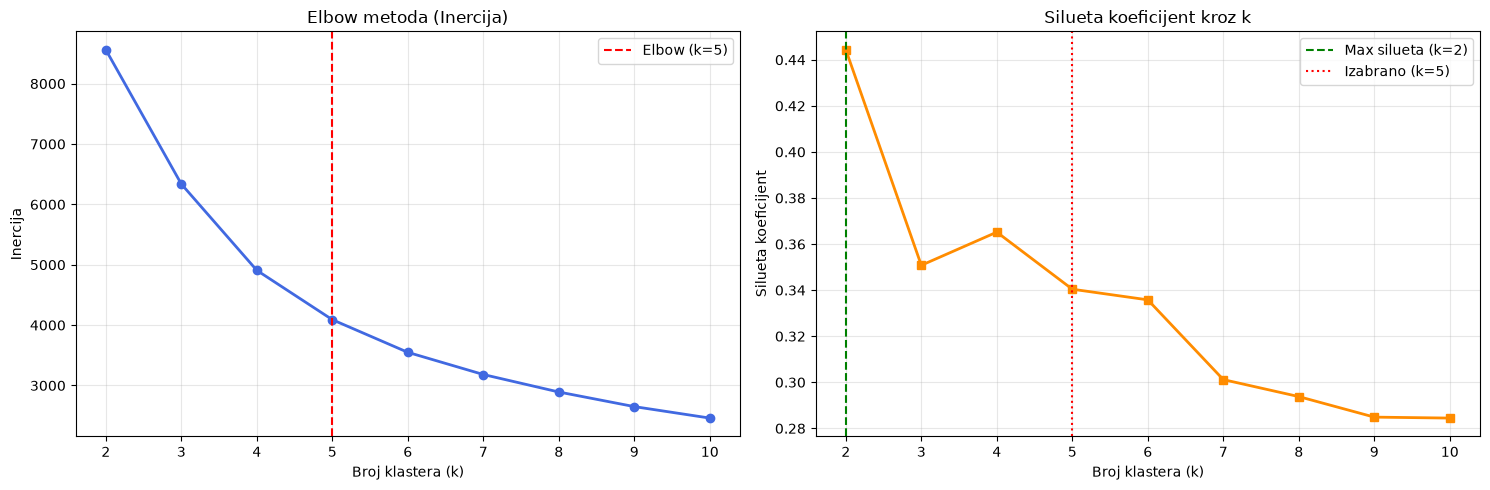

In [3]:
k_range = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x_skalirano)
    sil = silhouette_score(x_skalirano, labels, sample_size=3000, random_state=42)
    inertias.append(model.inertia_)
    silhouettes.append(sil)
    print(f"k={k:2d}: inercija={model.inertia_:>8.0f}  silueta={sil:.3f}")

# Crtanje grafika
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow kriva
ax1.plot(k_range, inertias, marker="o", color="royalblue", linewidth=2)
ax1.axvline(5, color="red", linestyle="--", label="Elbow (k=5)")
ax1.set_xlabel("Broj klastera (k)")
ax1.set_ylabel("Inercija")
ax1.set_title("Elbow metoda (Inercija)")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Silueta kriva
ax2.plot(k_range, silhouettes, marker="s", color="darkorange", linewidth=2)
ax2.axvline(2, color="green", linestyle="--", label="Max silueta (k=2)")
ax2.axvline(5, color="red", linestyle=":", label="Izabrano (k=5)")
ax2.set_xlabel("Broj klastera (k)")
ax2.set_ylabel("Silueta koeficijent")
ax2.set_title("Silueta koeficijent kroz k")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

❓ **Pitanje 1: Silueta kaže k=2, elbow kaže k=5. Koji biramo i zašto?**
- **Silueta za k=2 (0.444)** je matematički najviša jer algoritam podatke najlakše deli na dve grube grupe („aktivni/dobri kupci“ naspram „neaktivni/loši kupci“). Međutim, takva binarna podela nema praktičnu poslovnu vrednost jer marketinški tim ne može da kreira ciljane strategije na samo 2 masovne grupe.
- **Elbow metoda jasno pokazuje prelom na k=5** (inercija pada sa 8562 na 4090, nakon čega se smanjenje usporava).
- Zato biramo **k = 5**, jer pruža optimalan balans između matematičke separacije i poslovne primenljivosti (dobijamo jasne grupe: VIP, lojalni, uspavani, povremeni i neaktivni kupci).

## 4.3 Klasterovanje (k=5) i poslovna interpretacija

In [4]:
# Obučavanje modela sa k=5
model = KMeans(n_clusters=5, random_state=42, n_init=10)
rfm["Klaster"] = model.fit_predict(x_skalirano)

# Dodeljivanje poslovnih imena na osnovu profila
mapa_klastera = {
    0: "Neaktivni kupci",
    1: "Lojalni kupci",
    2: "VIP kupci",
    3: "Uspavani kupci",
    4: "Povremeni kupci"
}
rfm["KlasterIme"] = rfm["Klaster"].map(mapa_klastera)

# Prikaz profila klastera
profil = rfm.groupby("KlasterIme").agg(
    Kupaca=("CustomerID", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Prihod=("Monetary", "sum"))

profil["% kupaca"] = (profil.Kupaca / profil.Kupaca.sum() * 100).round(1)
profil["% prihoda"] = (profil.Prihod / profil.Prihod.sum() * 100).round(1)

print("Profil K-Means klastera:")
print(profil.round(1).sort_values("% prihoda", ascending=False))

Profil K-Means klastera:
                 Kupaca  Recency  Frequency  Monetary     Prihod  % kupaca  \
KlasterIme                                                                   
VIP kupci           454     17.3       32.6   20635.5  9368515.7       7.8   
Lojalni kupci      1284     48.8        9.1    3627.2  4657379.3      21.9   
Uspavani kupci     1352    288.7        3.8    1375.0  1858990.0      23.1   
Povremeni kupci    1141     32.5        2.5     666.2   760120.4      19.5   
Neaktivni kupci    1621    415.6        1.2     261.3   423577.3      27.7   

                 % prihoda  
KlasterIme                  
VIP kupci             54.9  
Lojalni kupci         27.3  
Uspavani kupci        10.9  
Povremeni kupci        4.5  
Neaktivni kupci        2.5  


❓ **Pitanje 2: Opis svakog klastera u jednoj rečenici za direktora prodaje:**

1. **VIP kupci (7.8% kupaca, 54.9% prihoda)**: Naši najvredniji kupci koji u proseku kupuju svakih 17 dana, imaju preko 32 porudžbine i prosečnu potrošnju veću od 20.600 £.
2. **Lojalni kupci (21.9% kupaca, 27.3% prihoda)**: Stabilna baza stalnih kupaca koji naručuju svakih mesec i po dana (~49 dana), sa prosečno 9 porudžbina i potrošnjom od oko 3.600 £.
3. **Uspavani kupci (23.1% kupaca, 10.9% prihoda)**: Kupci koji su ranije imali solidnu istoriju (prosečno 4 kupovine i 1.375 £), ali nisu kupovali skoro 10 meseci (289 dana) i zahtevaju reaktivaciju.
4. **Povremeni kupci (19.5% kupaca, 4.5% prihoda)**: Nedavni kupci (poslednja kupovina pre 33 dana) koji naručuju retko (2-3 puta) sa manjim iznosima (~666 £), te predstavljaju potencijal za razvoj lojalnosti.
5. **Neaktivni kupci (27.7% kupaca, 2.5% prihoda)**: Najbrojnija grupa kupaca koji su obavili samo 1 kupovinu male vrednosti (~261 £) pre više od 14 meseci (416 dana) i praktično su izgubljeni.

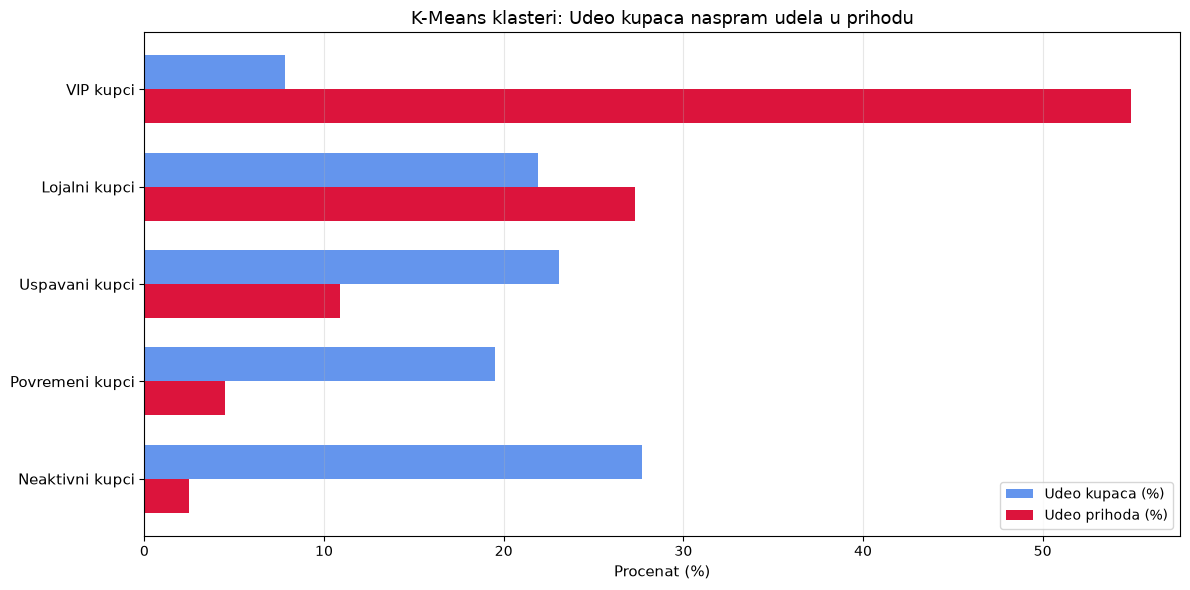

In [5]:
# Vizuelizacija strukture klastera: % kupaca vs % prihoda
profil_sorted = profil.sort_values("% prihoda", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(profil_sorted))
height = 0.35

ax.barh(y + height/2, profil_sorted["% kupaca"], height=height, label="Udeo kupaca (%)", color="cornflowerblue")
ax.barh(y - height/2, profil_sorted["% prihoda"], height=height, label="Udeo prihoda (%)", color="crimson")

ax.set_yticks(y)
ax.set_yticklabels(profil_sorted.index, fontsize=11)
ax.set_xlabel("Procenat (%)", fontsize=11)
ax.set_title("K-Means klasteri: Udeo kupaca naspram udela u prihodu", fontsize=13)
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

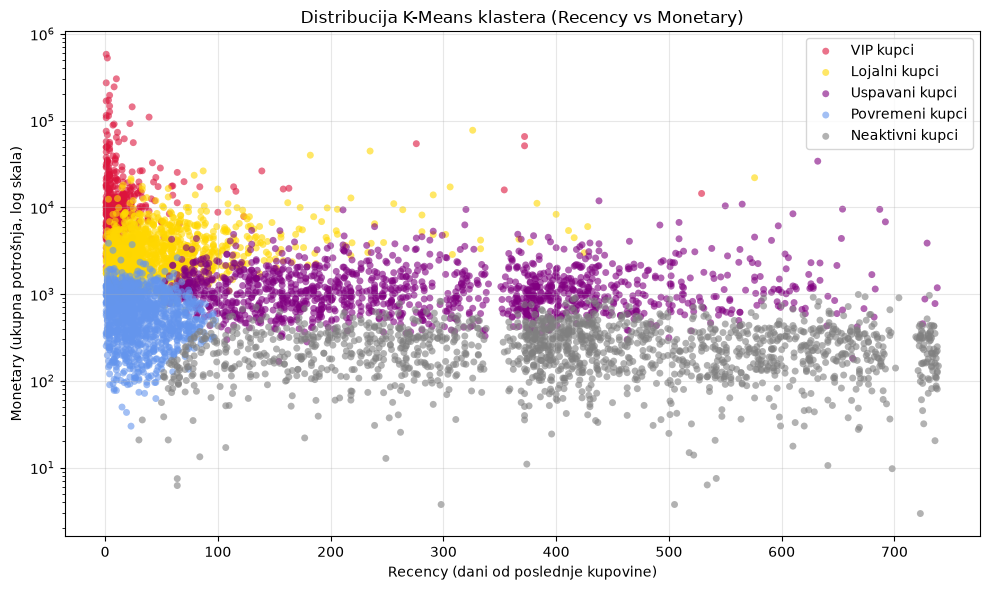

In [6]:
# Scatter plot klastera: Recency vs Monetary (sa Frequency kao veličinom tačke)
fig, ax = plt.subplots(figsize=(10, 6))

boje = {"VIP kupci": "crimson", "Lojalni kupci": "gold", "Uspavani kupci": "purple", 
        "Povremeni kupci": "cornflowerblue", "Neaktivni kupci": "gray"}

for ime, boja in boje.items():
    podskup = rfm[rfm.KlasterIme == ime]
    ax.scatter(podskup["Recency"], podskup["Monetary"], label=ime, color=boja, alpha=0.6, edgecolors="none", s=25)

ax.set_yscale("log")
ax.set_xlabel("Recency (dani od poslednje kupovine)")
ax.set_ylabel("Monetary (ukupna potrošnja, log skala)")
ax.set_title("Distribucija K-Means klastera (Recency vs Monetary)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.4 Poređenje K-Means klastera sa RFM segmentima iz Dana 3

In [7]:
# Unakrsna tabela (crosstab)
uporedna_tabela = pd.crosstab(rfm["Segment"], rfm["KlasterIme"])
print("Unakrsna raspodela kupaca (RFM segmenti vs K-Means klasteri):\n")
print(uporedna_tabela)

Unakrsna raspodela kupaca (RFM segmenti vs K-Means klasteri):

KlasterIme            Lojalni kupci  Neaktivni kupci  Povremeni kupci  \
Segment                                                                 
Izgubljeni                        0             1295                0   
Lojalni                         805                1               77   
Ne smemo ih izgubiti             33                0                0   
Novi kupci                        0                0               51   
Obecavajuci                       0                7              109   
Potencijalno lojalni             42                5              661   
Sampioni                        392                0               76   
Treba im paznja                   7               19               49   
U riziku                          5              102                0   
Uspavani                          0              192              118   

KlasterIme            Uspavani kupci  VIP kupci  
Segment   

❓ **Pitanje 3: Da li se K-Means i RFM segmenti poklapaju? Gde se najviše razilaze?**
- **Glavno poklapanje:** Postoji snažno preklapanje na ekstremima:
  - Većina RFM *Šampiona* završava u klasterima **VIP kupci** (362) i **Lojalni kupci** (392).
  - RFM *Lojalni* se dominantno prelivaju u K-Means **Lojalne kupce** (805).
  - RFM *Izgubljeni* se u potpunosti nalaze među **Neaktivnim kupcima** (1.295) i delom u **Uspavanim kupcima** (215).
- **Glavno razilaženje:**
  - RFM segmentacija koristi isključivo $R$ i $F$ za određivanje segmenta (Monetary se uopšte ne koristi za dodelu imena segmenta, već samo za naknadni sažetak).
  - K-Means istovremeno u obzir uzima sve tri dimenzije ($R$, $F$ i $M$) kao kontinuirane varijable. Zato kupac koji po RFM-u spada u „Lojalne“ ali ima enormnu potrošnju, u K-Means modelu biva prepoznat kao „VIP kupac“.

---

❓ **Pitanje 4: Koji pristup biste koristili u praksi i za šta? (Prednosti svakog)**
- **RFM segmentacija (Heuristička pravila):**
  - *Prednost:* Izuzetno intuitivna, transparentna i jednostavna za objašnjenje menadžmentu i primenu u CRM softverima (automatizovani e-mail tokovi tipa „Novi kupac -> pošalji popust dobrodošlice“).
  - *Kada koristiti:* Za svakodnevne operativne marketinške kampanje i brzu segmentaciju.
- **K-Means klasterovanje (Mašinsko učenje):**
  - *Prednost:* Nema proizvoljnih granica binova; objektivno pronalazi stvarna grupisanja i anomalije u multivarijantnom prostoru uzimajući u obzir i novčanu vrednost.
  - *Kada koristiti:* Za strateško planiranje budžeta, definisanje nivoa korisničke podrške (npr. dodela account managera VIP klasteru) i analizu dugoročne vrednosti kupaca (LTV).

In [8]:
# Snimanje obogaćene RFM tabele sa K-Means klasterima
rfm.to_parquet("../data/rfm_klasteri.parquet", index=False)
print("Tabela sa klasterima uspešno sačuvana u ../data/rfm_klasteri.parquet!")

Tabela sa klasterima uspešno sačuvana u ../data/rfm_klasteri.parquet!
